In [1]:
import pandas as pd

df = pd.read_csv("../data/Housing.csv")

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape:
(545, 13)

Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Data Types:
price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object


In [3]:
# Separate input features and target

X = df.drop("price", axis=1)
y = df["price"]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Input Features:
['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Target:
price


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (436, 12)
Testing data shape: (109, 12)


In [5]:
# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Categorical Features:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


C:\Users\Welcome\AppData\Local\Temp\ipykernel_13992\2074372584.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformers
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Combine preprocessing and model
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

print("Complete ML pipeline created successfully!")

Complete ML pipeline created successfully!


In [8]:
# Train the complete pipeline
model_pipeline.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [9]:
from sklearn.metrics import mean_absolute_error, r2_score

# Predict house prices
y_pred = model_pipeline.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 3))

Mean Absolute Error: 1025961.17
R2 Score: 0.61


In [10]:
# Get feature names after preprocessing
feature_names = model_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance from Random Forest
importances = model_pipeline.named_steps[
    "model"
].feature_importances_

# Display features in descending order of importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

importance_df

,Feature,Importance
0,num__area,0.465734
2,num__bathrooms,0.151184
4,num__parking,0.055437
3,num__stories,0.054202
1,num__bedrooms,0.046673
13,cat__airconditioning_no,0.034525
19,cat__furnishingstatus_unfurnished,0.033962
14,cat__airconditioning_yes,0.028036
9,cat__basement_no,0.017893
16,cat__prefarea_yes,0.016507


In [11]:
import matplotlib.pyplot as plt

importance_df.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("Feature Importance - Housing Price Prediction")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

Matplotlib is building the font cache; this may take a moment.


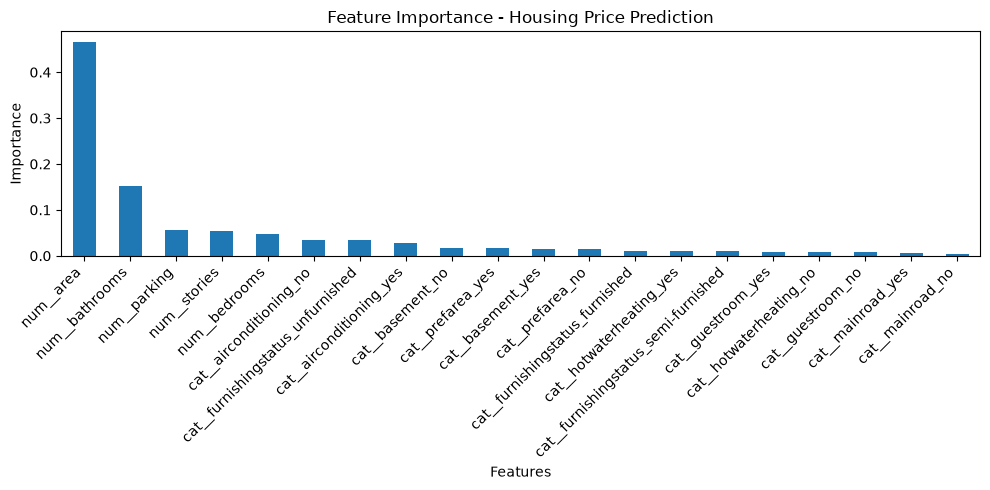

In [12]:
import matplotlib.pyplot as plt

importance_df.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("Feature Importance - Housing Price Prediction")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [13]:
results = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})

results.to_csv("../prediction_results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [14]:
results = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})

results.to_csv("../prediction_results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!
